In [5]:
from sklearn.datasets import load_iris

iris = load_iris()

print("Numărul de exemple și caracteristici (rânduri, coloane):", iris.data.shape)
print("Denumirile atributelor (coloanelor):", iris.feature_names)
print("Numele claselor (speciilor):", iris.target_names)

Numărul de exemple și caracteristici (rânduri, coloane): (150, 4)
Denumirile atributelor (coloanelor): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Numele claselor (speciilor): ['setosa' 'versicolor' 'virginica']


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)

print("Forma datelor de antrenament:", X_train.shape)
print("Forma datelor de testare:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nPrimele 3 exemple ÎNAINTE de scalare:\n", X_train[:3])
print("\nPrimele 3 exemple DUPĂ scalare:\n", X_train_scaled[:3])

Forma datelor de antrenament: (120, 4)
Forma datelor de testare: (30, 4)

Primele 3 exemple ÎNAINTE de scalare:
 [[6.4 3.1 5.5 1.8]
 [5.2 4.1 1.5 0.1]
 [5.4 3.4 1.5 0.4]]

Primele 3 exemple DUPĂ scalare:
 [[ 0.70202101  0.13405605  1.02897177  0.84421264]
 [-0.73597366  2.53505988 -1.25129808 -1.41588419]
 [-0.49630788  0.8543572  -1.25129808 -1.01704357]]


In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print(f"Acuratețea modelului cu k=3: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Matricea de confuzie:\n", confusion_matrix(y_test, y_pred))
print("\nRaport de clasificare:\n", classification_report(y_test, y_pred, target_names=iris.target_names))

Acuratețea modelului cu k=3: 96.67%

Matricea de confuzie:
 [[ 9  0  0]
 [ 0  8  0]
 [ 0  1 12]]

Raport de clasificare:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         9
  versicolor       0.89      1.00      0.94         8
   virginica       1.00      0.92      0.96        13

    accuracy                           0.97        30
   macro avg       0.96      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



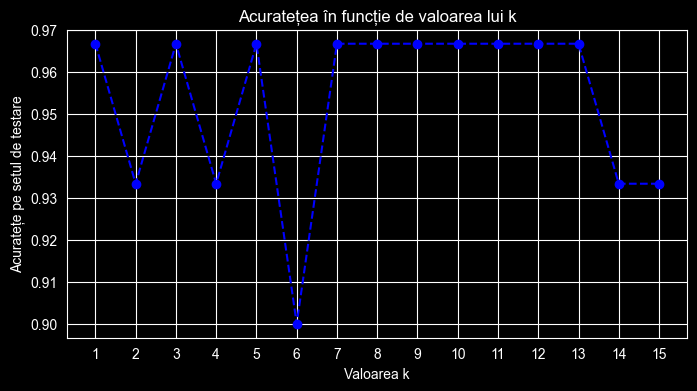

In [17]:
import matplotlib.pyplot as plt

accuracies = []
k_values = range(1, 16)

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    score = knn_temp.score(X_test_scaled, y_test)
    accuracies.append(score)

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='dashed', color='b')
plt.title('Acuratețea în funcție de valoarea lui k')
plt.xlabel('Valoarea k')
plt.ylabel('Acuratețe pe setul de testare')
plt.xticks(k_values)
plt.grid(True)
plt.show()

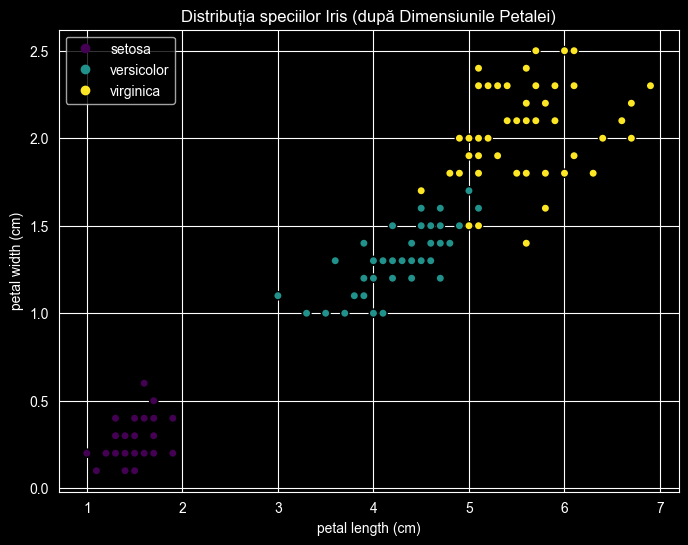

In [5]:
X_petala = X[:, 2:4]

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_petala[:, 0], X_petala[:, 1], c=y, cmap='viridis', edgecolor='k')

plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.title('Distribuția speciilor Iris (după Dimensiunile Petalei)')

plt.legend(handles=scatter.legend_elements()[0], labels=iris.target_names.tolist())
plt.show()

In [18]:
print("--- TESTEAZĂ O FLOARE NOUĂ ---")
try:
    sepal_length = float(input("Introdu lungimea sepalei (cm): "))
    sepal_width = float(input("Introdu lățimea sepalei (cm): "))
    petal_length = float(input("Introdu lungimea petalei (cm): "))
    petal_width = float(input("Introdu lățimea petalei (cm): "))

    floare_noua = [[sepal_length, sepal_width, petal_length, petal_width]]
    floare_noua_scaled = scaler.transform(floare_noua)
    pred_index = knn.predict(floare_noua_scaled)[0]
    specia_prezisa = iris.target_names[pred_index]

    print(f"\n=> Modelul a prezis că floarea ta este din specia: {specia_prezisa.upper()}")
except ValueError:
    print("Eroare: Te rog să introduci doar numere valide (folosește punctul pentru zecimale, ex: 1.5).")

--- TESTEAZĂ O FLOARE NOUĂ ---


KeyboardInterrupt: Interrupted by user